# DSSAT CROPGRO-Soybean emulator: what it does and how to use it

`cropemu` ships an emulator of **DSSAT 4.8 CROPGRO-Soybean**: a neural network trained on ~118,000 simulated
seasons at ~2,000 points of the world soybean area (NASA POWER weather, SoilGrids soil, GGCMI
calendar). It predicts the phenology, yield, biomass and water balance of a season from the
weather, the soil, the sowing date and the cultivar, in microseconds instead of the
0.1-1 s of the crop model, and without installing it.

This notebook is a tour of the library with one site (Londrina, Brazil) and one region:

1. the emulator: outputs, units, validation error, training domain;
2. weather and soil of a site;
3. one season, and how to read a prediction;
4. 35 years at a fixed sowing date;
5. the sowing window (year × sowing date);
6. cultivars and parameter sensitivity;
7. water: rainfed vs. irrigated;
8. climate scenarios (warming, CO₂, rain);
9. a regional map;
10. speed.

Everything here runs with `pip install "cropemu[soil]"`; weather and soil are downloaded once and
cached (`CROPEMU_CACHE`, default `~/.cache/cropemu`).

In [1]:
try:
    import cropemu
except ImportError:                       # install from PyPI (Intel Macs need --prefer-binary for rasterio)
    %pip install --quiet --prefer-binary "cropemu[soil]"
    import cropemu

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cropemu.weather import fetch, fill_gaps
from cropemu.soil import soilgrids, hydraulics

print("cropemu", cropemu.__version__, "| emulators:", cropemu.available())

cropemu 0.1.0 | emulators: ['aquacrop-soybean-v1', 'dssat-soybean-v1']


In [2]:
# figure style: recessive axes, fixed colour order
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
LEVEL_COLOR = {"recommended": "#0ca30c", "caution": "#fab219", "not recommended": "#d03b3b"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "0.9", "grid.linewidth": 0.6, "axes.edgecolor": "0.6",
                     "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
                     "legend.fontsize": 8, "legend.frameon": False, "figure.dpi": 110,
                     "axes.prop_cycle": plt.cycler(color=SERIES)})

YLD, MAT, FLO, ET, RAIN, BIO = 'HWAM', 'MDAT_dap', 'ADAT_dap', 'ETCM', 'PRCM', 'CWAM'
TO_T = 1e-3            # yield to t/ha
BIO_T = 1e-3           # biomass to t/ha

## 1. The emulator

In [3]:
emu = cropemu.load('dssat-soybean-v1')
print(emu)
print("trained on:", emu.card["training"]["seasons"], "seasons at", emu.card["training"]["points"], "points")
print("validation:", emu.card["validation"])
print("soil water retention:", emu.card["hydraulics"], "| cultivar parameters:", emu.cultivar_)
desc = emu.describe()
desc.round(3)

Emulator('dssat-soybean-v1': DSSAT 4.8 CROPGRO-Soybean (official executable), soybean; 79 inputs, 39 outputs)
trained on: 117720 seasons at 1962 points
validation: 5-fold cross-validation by 5-degree spatial blocks (out-of-fold metrics)
soil water retention: hybrid | cultivar parameters: ['mg', 'CSDL', 'PPSEN', 'EM-FL', 'FL-SH', 'FL-SD', 'SD-PM', 'FL-LF', 'LFMAX', 'SLAVR', 'SIZLF', 'WTPSD', 'SFDUR', 'SDPDV']


,description,unit,level,rmse,r2
output,,,,,
EDAT_dap,emergence date,days after sowing,recommended,3.553,0.878
ADAT_dap,anthesis (flowering) date,days after sowing,recommended,3.199,0.972
MDAT_dap,physiological maturity date,days after sowing,recommended,3.287,0.982
HDAT_dap,harvest date,days after sowing,caution,7.654,0.909
DWAP,planting material weight,kg/ha,recommended,0.453,0.989
CWAM,tops (above-ground) dry weight at maturity,kg/ha,caution,715.241,0.959
HWAM,grain yield at maturity (dry),kg/ha,caution,453.751,0.944
HWAH,harvested grain yield (dry),kg/ha,caution,452.705,0.944
PWAM,pod weight at maturity,kg/ha,caution,576.070,0.945


In [4]:
EMU_FAMILY = 'dssat'

Every output has an **acceptance level** from the spatial block validation (the network was tested
on 5° blocks it never saw):

- *recommended*: dates with RMSE ≤ 5 days, other outputs with RMSE < 0.25 of their within-site
  standard deviation;
- *caution*: relative error < 0.5;
- *not recommended*: use only as a rough indication.

The figure shows the validation R² of every output.

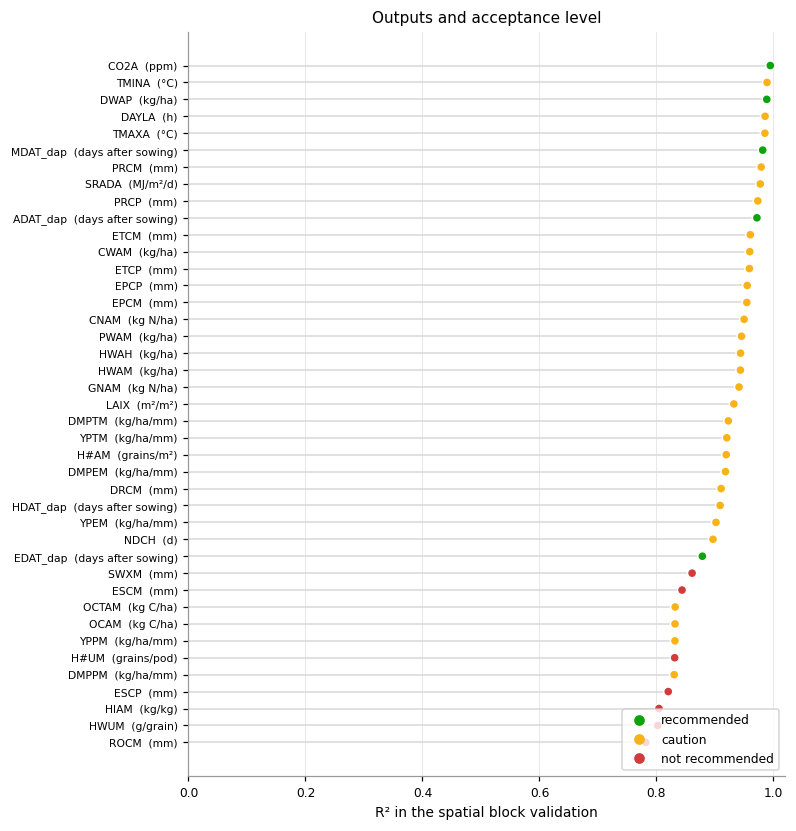

level
caution            29
not recommended     7
recommended         5


In [5]:
d = desc.dropna(subset=["r2"]).sort_values("r2")
fig, ax = plt.subplots(figsize=(7, 0.19 * len(d) + 1))
y = np.arange(len(d))
ax.hlines(y, 0, d["r2"].clip(lower=0), color="0.85", lw=1)
ax.scatter(d["r2"].clip(lower=0), y, s=36, color=[LEVEL_COLOR.get(l, "0.6") for l in d["level"]],
           edgecolor="white", linewidth=1, zorder=3)
ax.set_yticks(y, [f"{i}  ({u})" if u else i for i, u in zip(d.index, d["unit"])], fontsize=7)
ax.set(xlim=(0, 1.02), xlabel="R² in the spatial block validation", title="Outputs and acceptance level")
ax.grid(axis="y", visible=False)
ax.legend([plt.Line2D([], [], ls="", marker="o", color=v) for v in LEVEL_COLOR.values()], list(LEVEL_COLOR),
          loc="lower right", frameon=True)
plt.show()
print(d["level"].value_counts().to_string())

**Training domain.** The card stores the range of every input (min-max and 0.5-99.5 %).
Predictions report inputs outside it. The bars show the ranges of a few inputs.

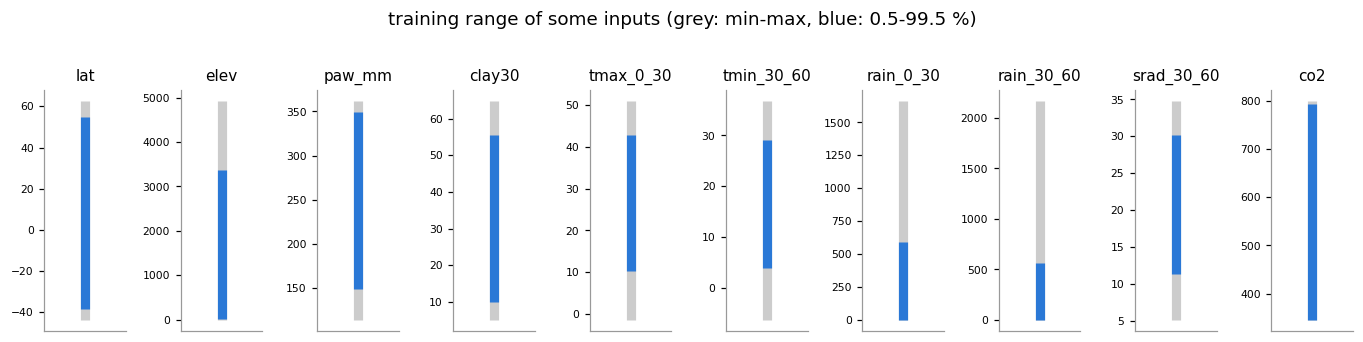

In [6]:
dom = pd.DataFrame(emu.card["domain"]).T
show = ["lat", "elev", "paw_mm", "clay30", "tmax_0_30", "tmin_30_60", "rain_0_30", "rain_30_60", "srad_30_60", "co2"]
fig, axes = plt.subplots(1, len(show), figsize=(1.25 * len(show), 3))
for ax, k in zip(axes, show):
    r = dom.loc[k]
    ax.vlines(0, r["min"], r["max"], color="0.8", lw=6)
    ax.vlines(0, r["q005"], r["q995"], color="#2a78d6", lw=6)
    ax.set(title=k, xticks=[]); ax.tick_params(labelsize=7); ax.grid(False)
fig.suptitle("training range of some inputs (grey: min-max, blue: 0.5-99.5 %)", y=1.02)
fig.tight_layout(); plt.show()

## 2. Weather and soil of a site

In [7]:
SITE, LAT, LON = "Londrina, Brazil", -23.19, -51.18
REF_SOWING = "2020-10-20"
weather = fill_gaps(fetch(LAT, LON, "1984-01-01", "2025-12-31"))        # NASA POWER, daily
ELEV = weather.attrs.get("elev", 600)
soil = soilgrids.fetch(LAT, LON)                                        # SoilGrids 2.0, 6 layers to 2 m
hyd = hydraulics(soil, method=emu.card["hydraulics"])                   # water retention used in training
print(f"{SITE}: elevation {ELEV:.0f} m, {len(weather)} days of weather")
hyd[["top", "bottom", "clay", "sand", "soc", "bdod", "ll", "dul", "sat"]].round(3)

Londrina, Brazil: elevation 455 m, 15341 days of weather


,top,bottom,clay,sand,soc,bdod,ll,dul,sat
0,0,5,42.4,23.7,3.93,1.20,0.295,0.453,0.547
1,5,15,41.9,24.3,2.48,1.23,0.274,0.431,0.536
2,15,30,46.4,22.1,1.77,1.22,0.270,0.426,0.540
3,30,60,53.3,18.6,1.04,1.22,0.277,0.428,0.540
4,60,100,54.2,18.4,0.67,1.22,0.272,0.423,0.540
5,100,200,51.9,19.4,0.70,1.22,0.266,0.418,0.540


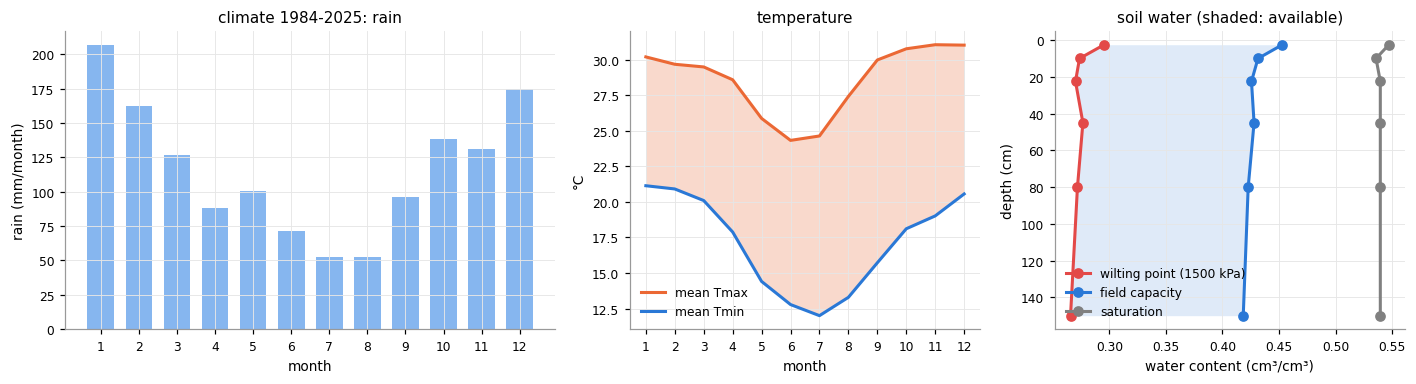

available water in 2 m: 306 mm


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.4, 1, 1]})
m = weather.groupby(weather.index.month).agg({"tmax": "mean", "tmin": "mean"})
rain = weather["rain"].groupby([weather.index.year, weather.index.month]).sum().groupby(level=1).mean()
ax = axes[0]
ax.bar(rain.index, rain, color="#86b6ef", width=0.7)
ax.set(xlabel="month", ylabel="rain (mm/month)", title="climate 1984-2025: rain")
ax.set_xticks(range(1, 13))
ax = axes[1]
ax.fill_between(m.index, m["tmin"], m["tmax"], color="#eb6834", alpha=0.25, lw=0)
ax.plot(m.index, m["tmax"], color="#eb6834", lw=2, label="mean Tmax")
ax.plot(m.index, m["tmin"], color="#2a78d6", lw=2, label="mean Tmin")
ax.set(xlabel="month", ylabel="°C", title="temperature"); ax.legend(); ax.set_xticks(range(1, 13))
ax = axes[2]
mid = (hyd["top"] + hyd["bottom"]) / 2
for col, lab, colr in (("ll", "wilting point (1500 kPa)", "#e34948"), ("dul", "field capacity", "#2a78d6"),
                       ("sat", "saturation", "0.5")):
    ax.plot(hyd[col], mid, marker="o", color=colr, lw=2, label=lab)
ax.fill_betweenx(mid, hyd["ll"], hyd["dul"], color="#2a78d6", alpha=0.15, lw=0)
ax.invert_yaxis(); ax.set(xlabel="water content (cm³/cm³)", ylabel="depth (cm)", title="soil water (shaded: available)")
ax.legend(loc="lower left")
fig.tight_layout(); plt.show()
paw = ((hyd["dul"] - hyd["ll"]) * (hyd["bottom"] - hyd["top"]) * 10).sum()
print(f"available water in 2 m: {paw:.0f} mm")

## 3. One season

### The cultivar

In DSSAT the cultivar is a set of 14 coefficients. `emu.cultivar(mg=...)` returns the
default coefficients of a maturity group (MG) from the CROPGRO-Soybean cultivar file;
`emu.cultivar(lat=...)` uses the typical MG of the latitude. Any coefficient can be overridden.

In [9]:
cult = emu.cultivar(lat=LAT)
cultivar_for = lambda mg: emu.cultivar(mg=mg)
pd.Series(cult).round(3).to_frame("value")

,value
mg,6.473
CSDL,12.462
PPSEN,0.315
EM-FL,20.484
FL-SH,9.473
FL-SD,16.000
SD-PM,35.978
FL-LF,18.000
LFMAX,1.030
SLAVR,375.000


In [10]:
res = emu.predict(weather, lat=LAT, elev=ELEV, soil=soil, sowing=REF_SOWING, cultivar=cult)
out = res.outputs.T.rename(columns=lambda d: f"sown {d:%Y-%m-%d}")
out = out.join(desc[["unit", "level"]]).round(3)
out

,sown 2020-10-20,unit,level
EDAT_dap,4.683,days after sowing,recommended
ADAT_dap,37.840,days after sowing,recommended
MDAT_dap,129.762,days after sowing,recommended
HDAT_dap,142.300,days after sowing,caution
DWAP,67.871,kg/ha,recommended
CWAM,4440.245,kg/ha,caution
HWAM,2653.344,kg/ha,caution
HWAH,2652.355,kg/ha,caution
PWAM,3531.516,kg/ha,caution
HWUM,0.192,g/grain,not recommended


A prediction carries, besides the outputs:

- `res.inputs`: the 80-odd inputs computed from weather, soil, sowing and cultivar (the same code as in training);
- `res.out_of_domain`: inputs outside the training range (do not trust the season);
- `res.rare_inputs`: inputs outside the 0.5-99.5 % range (less trust);
- `res.recommended("caution")`: only the outputs that passed the validation.

In [11]:
print("out of domain:", res.out_of_domain.iloc[0], "| rare:", res.rare_inputs.iloc[0])
res.recommended("recommended").round(2)

out of domain: [] | rare: []


,EDAT_dap,ADAT_dap,MDAT_dap,DWAP,CO2A
sowing,,,,,
2020-10-20,4.68,37.84,129.76,67.87,412.01


## 4. Thirty-five years at a fixed sowing date

In [12]:
YEARS = list(range(1990, 2025))
dates = [pd.Timestamp(y, 10, 20) for y in YEARS]
ts = emu.predict(weather, lat=LAT, elev=ELEV, soil=soil, sowing=dates, cultivar=cult)
o = ts.outputs.assign(year=YEARS).set_index("year")
irr = emu.predict(weather, lat=LAT, elev=ELEV, soil=soil, sowing=dates, cultivar=cult, irrigated=True).outputs
o["yield_t"] = o[YLD] * TO_T
o["yield_irrigated_t"] = irr[YLD].to_numpy() * TO_T
o[["yield_t", "yield_irrigated_t", MAT, ET, RAIN]].describe().round(2)

,yield_t,yield_irrigated_t,MDAT_dap,ETCM,PRCM
count,35.00,35.00,35.00,35.00,35.00
mean,4.85,5.77,126.07,672.85,891.97
std,1.22,0.33,3.63,42.86,226.10
min,1.56,5.07,114.53,556.02,532.43
25%,4.07,5.49,124.72,660.33,757.32
50%,5.39,5.88,126.67,675.21,872.19
75%,5.74,6.01,128.55,701.49,966.29
max,6.33,6.27,130.99,736.25,1561.30


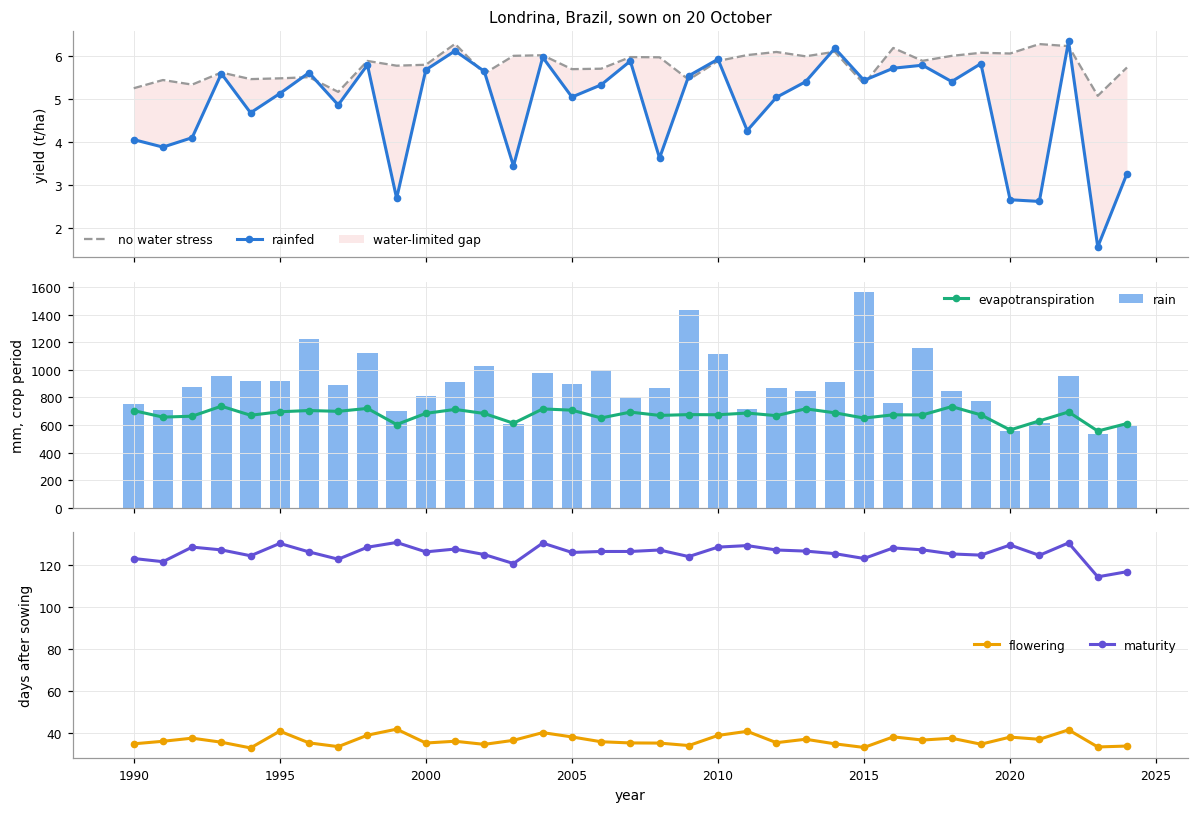

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True)
ax = axes[0]
ax.plot(o.index, o["yield_irrigated_t"], color="0.6", lw=1.5, ls="--", label="no water stress")
ax.plot(o.index, o["yield_t"], color="#2a78d6", lw=2, marker="o", markersize=4, label="rainfed")
ax.fill_between(o.index, o["yield_t"], o["yield_irrigated_t"], color="#e34948", alpha=0.12, lw=0, label="water-limited gap")
ax.set(ylabel="yield (t/ha)", title=f"{SITE}, sown on 20 October"); ax.legend(ncol=3)
ax = axes[1]
ax.bar(o.index, o[RAIN], color="#86b6ef", width=0.7, label="rain")
ax.plot(o.index, o[ET], color="#1baf7a", lw=2, marker="o", markersize=4, label="evapotranspiration")
ax.set(ylabel="mm, crop period"); ax.legend(ncol=2)
ax = axes[2]
ax.plot(o.index, o[FLO], color="#eda100", lw=2, marker="o", markersize=4, label="flowering")
ax.plot(o.index, o[MAT], color="#6250d6", lw=2, marker="o", markersize=4, label="maturity")
ax.set(ylabel="days after sowing", xlabel="year"); ax.legend(ncol=2)
fig.tight_layout(); plt.show()

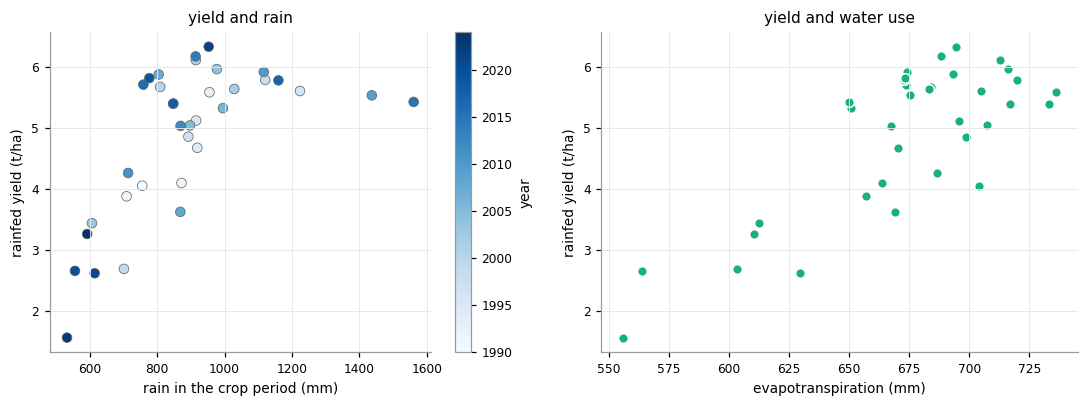

correlation yield-rain: 0.64, yield-ET: 0.79


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
ax = axes[0]
sc = ax.scatter(o[RAIN], o["yield_t"], c=o.index, cmap="Blues", s=40, edgecolor="0.4", linewidth=0.5)
ax.set(xlabel="rain in the crop period (mm)", ylabel="rainfed yield (t/ha)", title="yield and rain")
plt.colorbar(sc, ax=ax, label="year")
ax = axes[1]
ax.scatter(o[ET], o["yield_t"], s=40, color="#1baf7a", edgecolor="white")
ax.set(xlabel="evapotranspiration (mm)", ylabel="rainfed yield (t/ha)", title="yield and water use")
fig.tight_layout(); plt.show()
print(f"correlation yield-rain: {o['yield_t'].corr(o[RAIN]):.2f}, yield-ET: {o['yield_t'].corr(o[ET]):.2f}")

## 5. The sowing window

All sowing dates from 1 September to 31 December, every 4 days, in every year 1990-2024: about
1,000 seasons in a few seconds. The heat map shows the rainfed yield of each year and date; the
curve below, its median and the 25-75 % band (the risk).

In [15]:
offsets = range(0, 122, 4)
grid = [(y, pd.Timestamp(y, 9, 1) + pd.Timedelta(days=d)) for y in YEARS for d in offsets]
t0 = time.time()
sw = emu.predict(weather, lat=LAT, elev=ELEV, soil=soil, sowing=[g[1] for g in grid], cultivar=cult)
print(f"{len(grid)} seasons in {time.time() - t0:.1f} s")
W = pd.DataFrame({"year": [g[0] for g in grid], "day": [g[1].strftime("%m-%d") for g in grid],
                  "yield": sw.outputs[YLD].to_numpy() * TO_T, "mat": sw.outputs[MAT].to_numpy(),
                  "rare": sw.rare_inputs.str.len().to_numpy() > 0})
H = W.pivot(index="year", columns="day", values="yield")

1085 seasons in 0.8 s


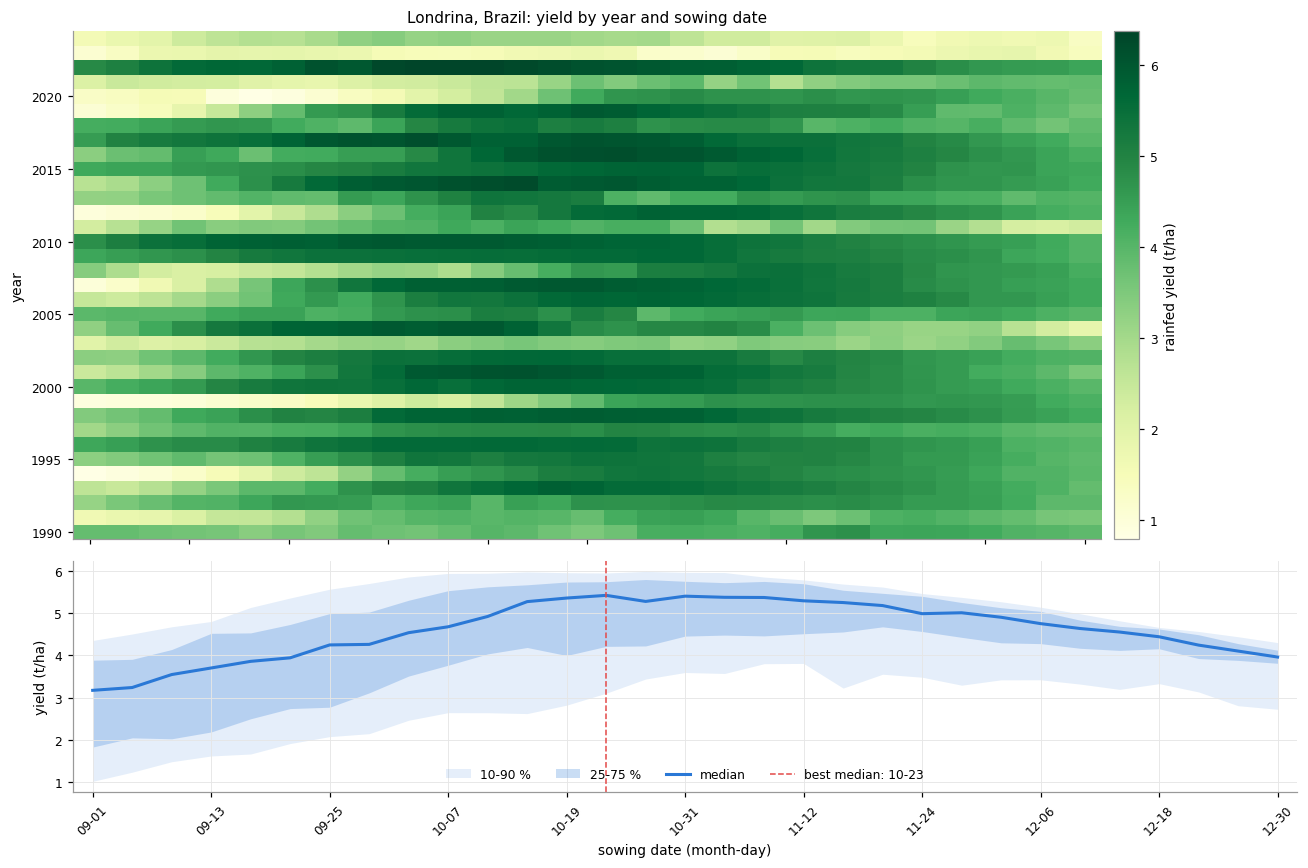

share of seasons with rare inputs: 10.0%


In [16]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), gridspec_kw={"height_ratios": [2.2, 1]}, sharex=True)
ax = axes[0]
im = ax.imshow(H.to_numpy(), aspect="auto", cmap="YlGn", origin="lower",
               extent=(-0.5, H.shape[1] - 0.5, H.index[0] - 0.5, H.index[-1] + 0.5))
plt.colorbar(im, ax=ax, label="rainfed yield (t/ha)", pad=0.01)
ax.set(ylabel="year", title=f"{SITE}: yield by year and sowing date"); ax.grid(False)
q = H.quantile([0.1, 0.25, 0.5, 0.75, 0.9]).T
x = np.arange(len(q))
ax = axes[1]
ax.fill_between(x, q[0.1], q[0.9], color="#2a78d6", alpha=0.12, lw=0, label="10-90 %")
ax.fill_between(x, q[0.25], q[0.75], color="#2a78d6", alpha=0.25, lw=0, label="25-75 %")
ax.plot(x, q[0.5], color="#2a78d6", lw=2, label="median")
best = int(np.argmax(q[0.5].to_numpy()))
ax.axvline(best, color="#e34948", lw=1, ls="--", label=f"best median: {q.index[best]}")
ax.set(ylabel="yield (t/ha)", xlabel="sowing date (month-day)"); ax.legend(ncol=4, loc="lower center")
ax.set_xticks(x[::3], q.index[::3], rotation=45)
fig.tight_layout(); plt.show()
print(f"share of seasons with rare inputs: {W['rare'].mean():.1%}")

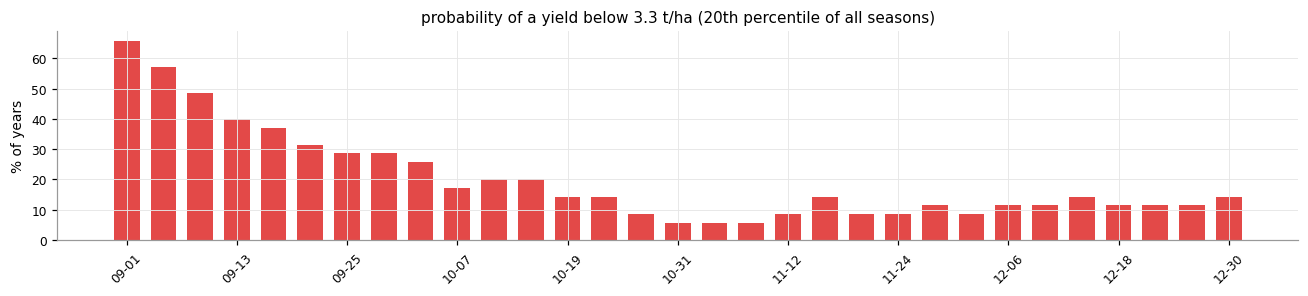

In [17]:
# risk: probability of a rainfed yield below a threshold, by sowing date
thr = float(np.nanpercentile(W["yield"], 20))
risk = (H < thr).mean()
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.bar(np.arange(len(risk)), risk * 100, color="#e34948", width=0.7)
ax.set_xticks(np.arange(len(risk))[::3], risk.index[::3], rotation=45)
ax.set(ylabel="% of years", title=f"probability of a yield below {thr:.1f} t/ha (20th percentile of all seasons)")
fig.tight_layout(); plt.show()

## 6. Cultivars

### 6.1 Maturity group

Maturity groups from 4.5 to 8.5 sown on the same date, 1990-2024. Later groups flower and mature
later (photoperiod), which changes the yield and its year-to-year variability.

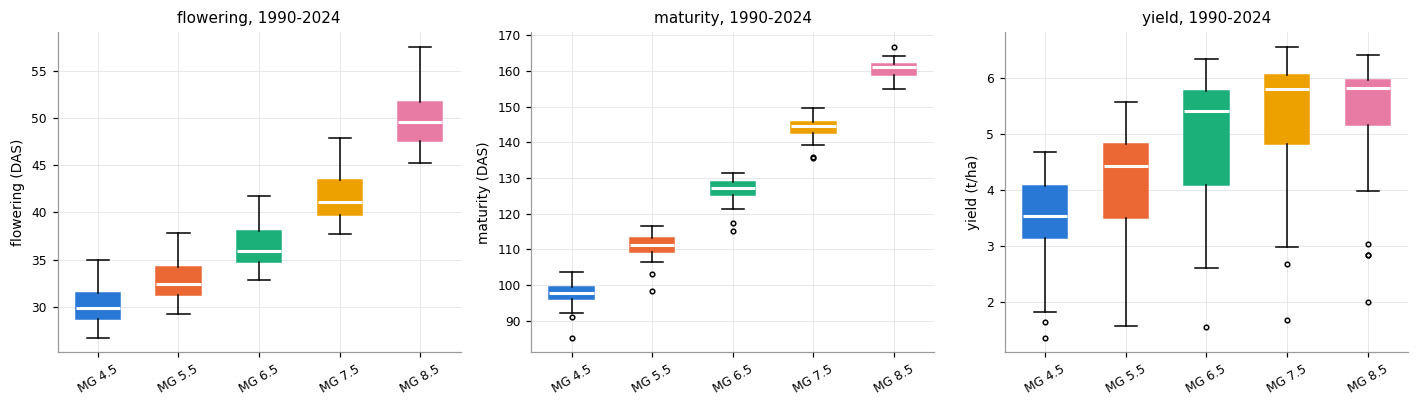

flowering       maturity       yield      
             mean   std     mean   std  mean   std
variant                                           
MG 4.5      30.24  2.23    97.62  3.61  3.47  0.86
MG 5.5      32.85  2.32   111.00  3.67  4.08  1.07
MG 6.5      36.45  2.47   126.51  3.62  4.87  1.22
MG 7.5      41.71  2.71   143.89  3.08  5.26  1.22
MG 8.5      49.90  3.13   160.59  2.33  5.29  1.13

In [18]:
variants = {f"MG {mg}": cultivar_for(mg) for mg in (4.5, 5.5, 6.5, 7.5, 8.5)}
rows = []
for name, cv in variants.items():
    r = emu.predict(weather, lat=LAT, elev=ELEV, soil=soil, sowing=dates, cultivar=cv).outputs
    rows.append(pd.DataFrame({"variant": name, "year": YEARS, "yield": r[YLD].to_numpy() * TO_T,
                              "flowering": r[FLO].to_numpy(), "maturity": r[MAT].to_numpy()}))
V = pd.concat(rows)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
names = list(variants)
for ax, col, lab in zip(axes, ("flowering", "maturity", "yield"), ("flowering (DAS)", "maturity (DAS)", "yield (t/ha)")):
    data = [V.loc[V["variant"] == n, col].dropna().to_numpy() for n in names]
    bp = ax.boxplot(data, tick_labels=names, widths=0.55, patch_artist=True,
                    medianprops=dict(color="white", lw=2), flierprops=dict(markersize=3))
    for patch, colr in zip(bp["boxes"], SERIES):
        patch.set(facecolor=colr, edgecolor=colr)
    ax.set(ylabel=lab, title=f"{lab.split(' (')[0]}, 1990-2024"); ax.tick_params(axis="x", labelrotation=30)
fig.tight_layout(); plt.show()
V.groupby("variant", sort=False)[["flowering", "maturity", "yield"]].agg(["mean", "std"]).round(2)

### 6.2 Parameter sensitivity

One parameter at a time across its training range, the others at their typical value; median and
25-75 % band over 1990-2024. The x-range is the 0.5-99.5 % range of the training data
(`card["domain"]`), so every point is inside the domain.

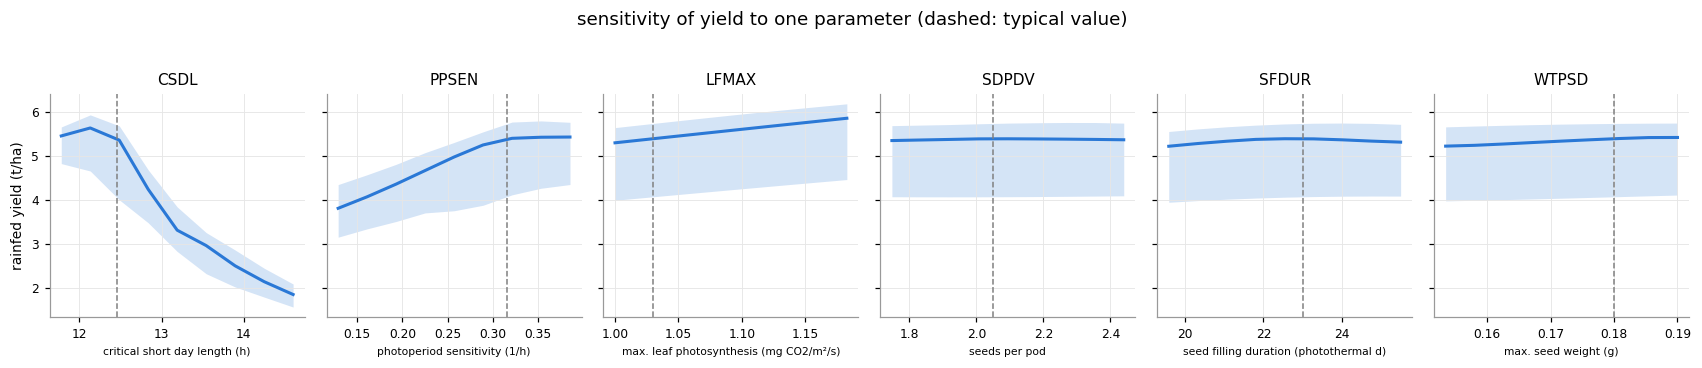

In [19]:
SENS = [('CSDL', 'critical short day length (h)'), ('PPSEN', 'photoperiod sensitivity (1/h)'), ('LFMAX', 'max. leaf photosynthesis (mg CO2/m²/s)'), ('SDPDV', 'seeds per pod'), ('SFDUR', 'seed filling duration (photothermal d)'), ('WTPSD', 'max. seed weight (g)')]
fig, axes = plt.subplots(1, len(SENS), figsize=(2.6 * len(SENS), 3.2), sharey=True)
for ax, (p, lab) in zip(axes, SENS):
    lo, hi = emu.card["domain"][p]["q005"], emu.card["domain"][p]["q995"]
    xs = np.linspace(lo, hi, 9)
    med, q1, q3 = [], [], []
    for v in xs:
        r = emu.predict(weather, lat=LAT, elev=ELEV, soil=soil, sowing=dates, cultivar={**cult, p: v}).outputs[YLD] * TO_T
        med.append(r.median()); q1.append(r.quantile(0.25)); q3.append(r.quantile(0.75))
    ax.fill_between(xs, q1, q3, color="#2a78d6", alpha=0.2, lw=0)
    ax.plot(xs, med, color="#2a78d6", lw=2)
    ax.axvline(cult[p], color="0.5", lw=1, ls="--")
    ax.set(title=p, xlabel=lab); ax.xaxis.label.set_size(7)
axes[0].set_ylabel("rainfed yield (t/ha)")
fig.suptitle("sensitivity of yield to one parameter (dashed: typical value)", y=1.03)
fig.tight_layout(); plt.show()

## 7. Water: rainfed vs. no water stress

`irrigated=True` predicts the season without water stress (the water balance switched off, as in
the training seasons without water limitation). The difference is the water-limited yield gap.

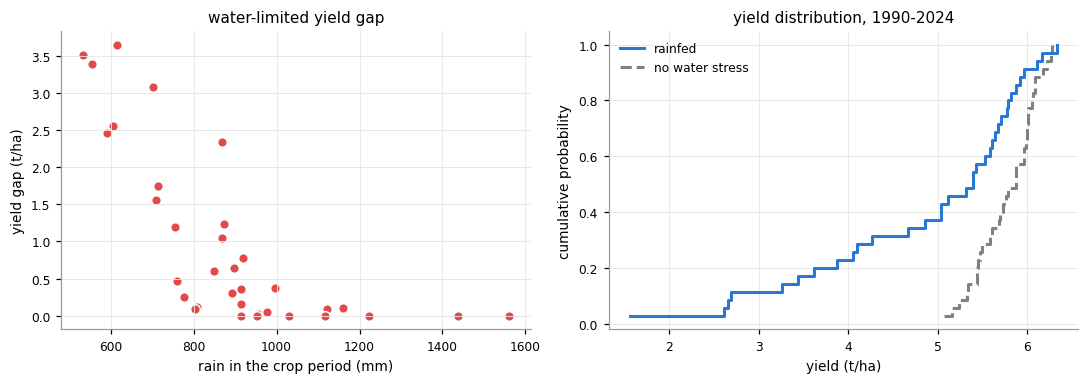

mean gap 0.94 t/ha (16% of the unstressed yield)


In [20]:
gap = (o["yield_irrigated_t"] - o["yield_t"]).clip(lower=0)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axes[0]
ax.scatter(o[RAIN], gap, s=40, color="#e34948", edgecolor="white")
ax.set(xlabel="rain in the crop period (mm)", ylabel="yield gap (t/ha)", title="water-limited yield gap")
ax = axes[1]
srt = np.sort(o["yield_t"]); srt_i = np.sort(o["yield_irrigated_t"])
p = np.arange(1, len(srt) + 1) / len(srt)
ax.step(srt, p, where="post", color="#2a78d6", lw=2, label="rainfed")
ax.step(srt_i, p, where="post", color="0.5", lw=2, ls="--", label="no water stress")
ax.set(xlabel="yield (t/ha)", ylabel="cumulative probability", title="yield distribution, 1990-2024"); ax.legend()
fig.tight_layout(); plt.show()
print(f"mean gap {gap.mean():.2f} t/ha ({gap.mean() / o['yield_irrigated_t'].mean():.0%} of the unstressed yield)")

## 8. Climate scenarios

The training seasons included perturbations: +-1 to +4 °C on Tmax and Tmin, rain x0.7-1.3 and CO₂
350-800 ppm. The same perturbations can be applied to the observed weather of the site
(`dt`, `rain_factor`, `co2`), which gives a quick climate-sensitivity analysis. The values are
changes of the mean yield 1990-2024 relative to the baseline (observed weather, Mauna Loa CO₂).

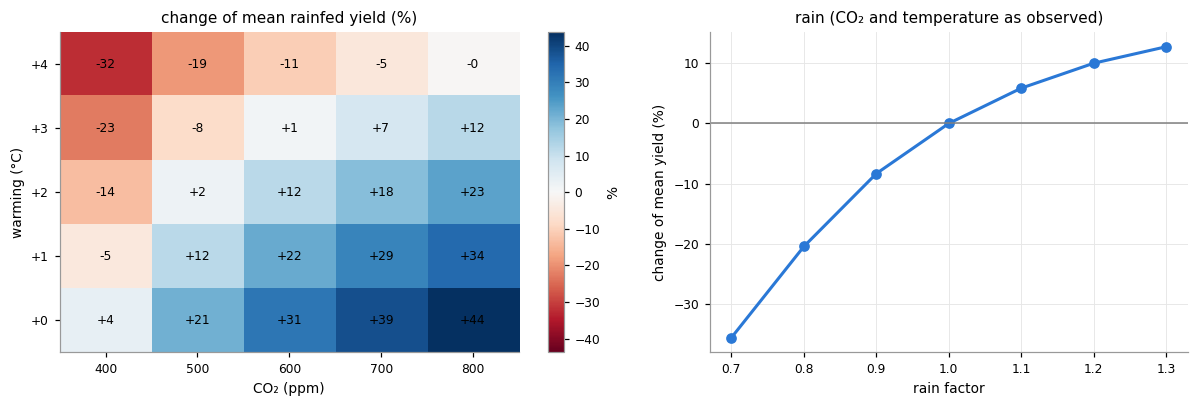

In [21]:
base = o["yield_t"].mean()
DTS, CO2S = [0, 1, 2, 3, 4], [400, 500, 600, 700, 800]
G = pd.DataFrame(index=DTS, columns=CO2S, dtype=float)
for dt in DTS:
    for co2 in CO2S:
        y = emu.predict(weather, lat=LAT, elev=ELEV, soil=soil, sowing=dates, cultivar=cult, dt=dt, co2=co2).outputs[YLD]
        G.loc[dt, co2] = 100 * (y.mean() * TO_T / base - 1)
RF = [0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3]
rf = [100 * (emu.predict(weather, lat=LAT, elev=ELEV, soil=soil, sowing=dates, cultivar=cult, rain_factor=f)
             .outputs[YLD].mean() * TO_T / base - 1) for f in RF]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
lim = np.nanmax(np.abs(G.to_numpy()))
im = ax.imshow(G.to_numpy(float), cmap="RdBu", vmin=-lim, vmax=lim, origin="lower", aspect="auto")
for i, dt in enumerate(DTS):
    for j, co2 in enumerate(CO2S):
        ax.text(j, i, f"{G.loc[dt, co2]:+.0f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(len(CO2S)), CO2S); ax.set_yticks(range(len(DTS)), [f"+{d}" for d in DTS])
ax.set(xlabel="CO₂ (ppm)", ylabel="warming (°C)", title="change of mean rainfed yield (%)"); ax.grid(False)
plt.colorbar(im, ax=ax, label="%")
ax = axes[1]
ax.plot(RF, rf, color="#2a78d6", lw=2, marker="o")
ax.axhline(0, color="0.5", lw=1)
ax.set(xlabel="rain factor", ylabel="change of mean yield (%)", title="rain (CO₂ and temperature as observed)")
fig.tight_layout(); plt.show()

## 9. A regional map

A 2° grid over the soybean area of southern and central Brazil. For each point: weather and soil
are downloaded (once; cached), the typical cultivar of the latitude is sown every 5 days from
15 September to 15 December in 2000-2024, and the median yield and the best sowing date are
mapped. Points without soil data (water, cities) are skipped.

In [22]:
lats = np.arange(-30.5, -11.4, 2.0)
lons = np.arange(-57.5, -44.4, 2.0)
pts = pd.DataFrame([(f"p{i}_{j}", la, lo) for i, la in enumerate(lats) for j, lo in enumerate(lons)],
                   columns=["id", "lat", "lon"])
t0 = time.time()
soils = soilgrids.fetch_many(pts, n_jobs=16)
YEARS_MAP = range(2000, 2025)
OFFS = range(0, 92, 5)
rows = []
for p in pts.itertuples():
    s = soils[p.id]
    if s[["clay", "sand", "soc", "bdod"]].isna().any().any():
        continue
    w = fill_gaps(fetch(p.lat, p.lon, "1999-01-01", "2025-12-31"))
    if EMU_FAMILY == "dssat":
        cv = emu.cultivar(lat=p.lat)
    else:
        cv = emu.cultivar(lat=p.lat, mg=emu.typical_mg(p.lat), weather=w, sowing="2020-11-01", cycle_days=CYCLE_DAYS)
    ds = [pd.Timestamp(y, 9, 15) + pd.Timedelta(days=d) for y in YEARS_MAP for d in OFFS]
    r = emu.predict(w, lat=p.lat, elev=w.attrs.get("elev"), soil=s, sowing=ds, cultivar=cv)
    t = pd.DataFrame({"off": [d for _ in YEARS_MAP for d in OFFS], "y": r.outputs[YLD].to_numpy() * TO_T})
    med = t.groupby("off")["y"].median()
    rows.append({"lat": p.lat, "lon": p.lon, "median_yield": med.max(), "best_day": int(med.idxmax()),
                 "cv": t.groupby("off")["y"].std().loc[med.idxmax()] / med.max(),
                 "rare": float((r.rare_inputs.str.len() > 0).mean()), "out": float((r.out_of_domain.str.len() > 0).mean())})
M = pd.DataFrame(rows)
print(f"{len(M)} points, {len(M) * len(YEARS_MAP) * len(OFFS)} seasons, {time.time() - t0:.0f} s (with downloads)")

62 points, 29450 seasons, 245 s (with downloads)


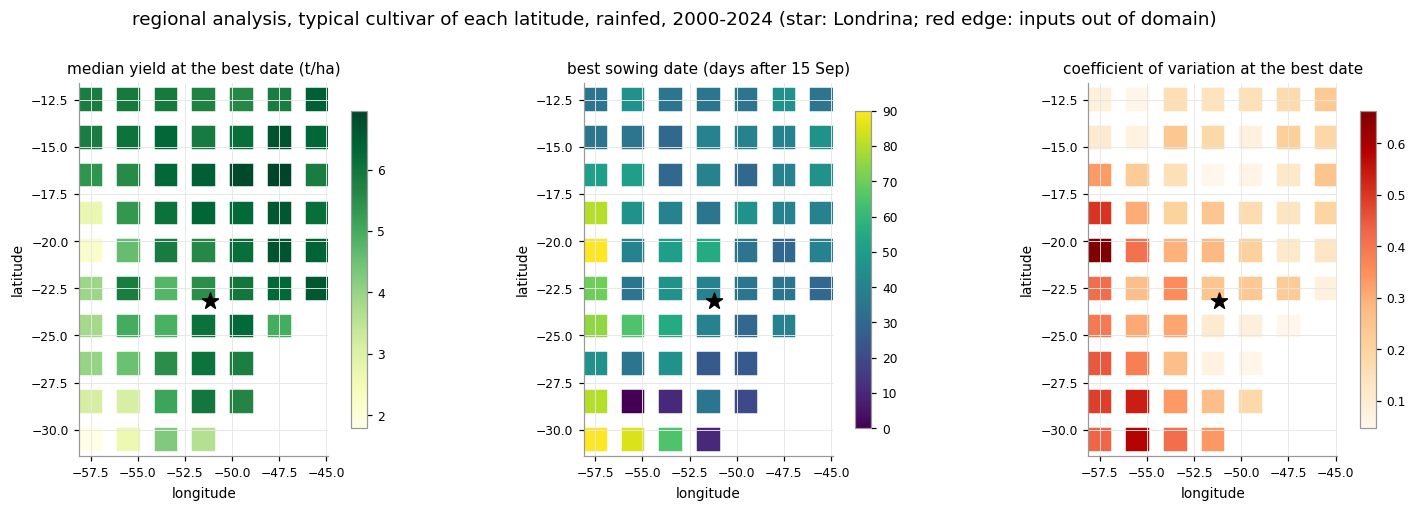

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
specs = [("median_yield", "YlGn", "median yield at the best date (t/ha)"),
         ("best_day", "viridis", "best sowing date (days after 15 Sep)"),
         ("cv", "OrRd", "coefficient of variation at the best date")]
for ax, (col, cmap, title) in zip(axes, specs):
    sc = ax.scatter(M["lon"], M["lat"], c=M[col], cmap=cmap, s=260, marker="s", edgecolor="white", linewidth=1)
    bad = M[M["out"] > 0]
    ax.scatter(bad["lon"], bad["lat"], s=260, marker="s", facecolor="none", edgecolor="#e34948", linewidth=1.5)
    ax.scatter([LON], [LAT], marker="*", s=120, color="k")
    plt.colorbar(sc, ax=ax, shrink=0.85)
    ax.set(title=title, xlabel="longitude", ylabel="latitude", aspect="equal")
fig.suptitle("regional analysis, typical cultivar of each latitude, rainfed, 2000-2024 (star: Londrina; red edge: inputs out of domain)", y=1.0)
fig.tight_layout(); plt.show()

## 10. Speed

In [24]:
X = sw.inputs
big = pd.concat([X] * 100, ignore_index=True)
t0 = time.time(); emu.predict_inputs(big); t_net = time.time() - t0
t0 = time.time(); emu.inputs(weather, lat=LAT, elev=ELEV, soil=soil, sowing=[g[1] for g in grid], cultivar=cult); t_in = time.time() - t0
print(f"network: {1e6 * t_net / len(big):.1f} µs per season ({len(big)} seasons in {t_net:.2f} s)")
print(f"inputs from daily weather: {1e3 * t_in / len(grid):.2f} ms per season")
print("the crop model itself takes ~0.1-1 s per season (plus writing and reading its files)")

network: 15.0 µs per season (108500 seasons in 1.63 s)
inputs from daily weather: 0.81 ms per season
the crop model itself takes ~0.1-1 s per season (plus writing and reading its files)


## Notes

- The emulator reproduces the crop model, not field yields: model errors are inherited, and the
  crop model was not calibrated for these sites.
- Fixed in training: 30 plants/m², 50 cm rows, no nitrogen stress, half of the available water 30
  days before sowing. Seasons with other management are outside what the emulator knows.
- Check `out_of_domain` and `rare_inputs` before trusting a season, and prefer the outputs of
  `recommended("caution")`.